<a href="https://colab.research.google.com/github/aisyashlf/Evaluating-Sequence-Learning-Performance-of-RNN-LSTM-and-Attention-Based-Models/blob/main/UAS_DeepLearning_Group6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas UAS Deep Learning 2025


| Nama | NIM |
|----------|----------|
| Rio Tri Wibowo  | 11220940000004   |
| Aisya Shalifa  | 11220940000032   |



-------------------------------------------------------------------


### **Perintah**
Diberikan suatu data sequential yang berisi panjang `INPUT` (berisi angka 0 sampai 9) dan blank (diisi angka 10) yang menandakan terdapat noise dari data. Kolom target berisi angka-angka yang sama dengan `INPUT`. Buatlah model RNN dan LSTM untuk memprediksi angka-angka yang terdapat di dalam `INPUT`. Kemudian selidiki dan bandingkan training loss pada kedua model tersebut. Serta lakukan evaluasi kedua model tersebut dengan lima sampel yang berbeda. Selidiki pula magnitude dari bobot pada masing-masing model (opsional) pada saat proses training.

Contoh:
Misalkan kita punya `INPUT` dengan panjang 5 dan `BLANK` dengan panjang 3

* INPUT = [2,  9,  2,  0,  0]
* BLANK = [10, 10, 10]
* SAMPLE DATA = INPUT $\cup$ BLANK = [2,  9,  2,  0,  0, 10, 10, 10]

Maka targetnya adalah

TARGET = INPUT = [2,  9,  2,  0,  0]

CONTOH EVALUASI:

| Sample data | Target | Predicted | Correct |
|----------|----------|-----------|---------|
| [ 2  1  9  8  0  4  9  0  6  0 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]    | [2 1 9 **8** 0 4 9 0 6 0]   | [8 8 8 **8** 8 8 8 8 8 8] | 1/10 (10.0%)

Keterangan:

* Panjang input = Panjang target = 10
* Panjang blank = 20
* Panjang sample data = Panjang input + Panjang blank = 30




CATATAN:
Gunakan gradient clipping untuk menghindari exloding gradient dengan cara menambahkan `torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)` pada proses training.




In [1]:
!pip install optuna pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import json
import os
import copy

from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [28]:
torch.manual_seed(123)
np.random.seed(123)

VOCAB_SIZE = 10
INPUT_LEN = 10
BLANK_LEN = 20
TOTAL_LEN = INPUT_LEN + BLANK_LEN

HIDDEN_SIZE = 1024
NUM_LAYERS = 4
NUM_EPOCHS = 100
BATCH_SIZE = 64
LEARNING_RATE = 0.001

MAX_GRAD_NORM = 1.0
EARLY_STOPPING_PATIENCE = 15

In [5]:
torch.manual_seed(123)
np.random.seed(123)

vocab_size = 10
input_len = 10
blank_len = 20
total_len = input_len + blank_len

hidden_size = 1024
num_layers = 4
num_epochs = 100
batch_size = 64
learning_rate = 0.001

max_grad_norm = 1.0
early_stopping_patience = 15

#**Generate Data**

In [36]:
def generate_batch(scenario="clean", batch_size=64):

    # Generate original sequences
    sequences = torch.randint(
        VOCAB_SIZE,
        (batch_size, INPUT_LEN),
        dtype=torch.long
    )

    # Generate blank positions
    blanks = torch.full(
        (batch_size, BLANK_LEN),
        VOCAB_SIZE,
        dtype=torch.long
    )

    # Apply noise
    if scenario == "noise_end":

        noise = torch.randint(
            VOCAB_SIZE,
            (batch_size, INPUT_LEN),
            dtype=torch.long
        )

        blanks[:, -INPUT_LEN:] = noise

    elif scenario == "noise_random":

        for i in range(batch_size):
            positions = torch.randperm(BLANK_LEN)[:INPUT_LEN]

            noise = torch.randint(
                VOCAB_SIZE,
                (INPUT_LEN,),
                dtype=torch.long
            )

            blanks[i, positions] = noise

    elif scenario != "clean":
        raise ValueError(f"Unknown scenario: {scenario}")

    # Combine sequence and blank positions
    inputs = torch.cat(
        (sequences, blanks),
        dim=1
    )

    # Original sequence as target
    targets = sequences.clone()

    return inputs.to(device), targets.to(device)

In [37]:
SCENARIOS = ["clean", "noise_end", "noise_random"]

DATASETS = {}

for scenario in SCENARIOS:

    train_inputs, train_targets = generate_batch(
        scenario=scenario,
        batch_size=5000
    )

    val_inputs, val_targets = generate_batch(
        scenario=scenario,
        batch_size=1000
    )

    test_inputs, test_targets = generate_batch(
        scenario=scenario,
        batch_size=1000
    )

    DATASETS[scenario] = {
        "train_inputs": train_inputs,
        "train_targets": train_targets,
        "val_inputs": val_inputs,
        "val_targets": val_targets,
        "test_inputs": test_inputs,
        "test_targets": test_targets
    }

print("Dataset berhasil dibuat!")

for scenario in DATASETS:
    print(
        scenario,
        DATASETS[scenario]["train_inputs"].shape
    )

Dataset berhasil dibuat!
clean torch.Size([5000, 30])
noise_end torch.Size([5000, 30])
noise_random torch.Size([5000, 30])


In [38]:
inputs, targets = generate_batch("noise_end")

print("Input shape:", inputs.shape)
print("Target shape:", targets.shape)

Input shape: torch.Size([64, 30])
Target shape: torch.Size([64, 10])


In [39]:
print(inputs[:2])

tensor([[ 0,  0,  8,  9,  5,  1,  1,  8,  8,  2, 10, 10, 10, 10, 10, 10, 10, 10,
         10, 10,  9,  5,  1,  1,  9,  3,  1,  3,  6,  8],
        [ 9,  9,  9,  6,  3,  8,  0,  7,  4,  9, 10, 10, 10, 10, 10, 10, 10, 10,
         10, 10,  2,  1,  1,  7,  2,  3,  5,  4,  5,  9]], device='cuda:0')


In [40]:
print(targets[:2])

tensor([[0, 0, 8, 9, 5, 1, 1, 8, 8, 2],
        [9, 9, 9, 6, 3, 8, 0, 7, 4, 9]], device='cuda:0')


## **DEFINE MODEL RNN & LSTM & LSTM ATTENTION**

In [41]:
class RNNModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        hidden_size,
        num_layers,
        dropout=0.0
    ):
        super().__init__()

        self.model_type = "RNN"

        self.embedding = nn.Embedding(
            vocab_size + 1,
            hidden_size
        )

        self.rnn = nn.RNN(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):

        embedded = self.embedding(x)

        rnn_out, hidden = self.rnn(embedded)

        logits = self.fc(rnn_out)

        return logits

In [42]:
class LSTMModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        hidden_size,
        num_layers,
        dropout=0.0
    ):
        super().__init__()

        self.model_type = "LSTM"

        self.embedding = nn.Embedding(
            vocab_size + 1,
            hidden_size
        )

        self.lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):

        embedded = self.embedding(x)

        lstm_out, (hidden, cell) = self.lstm(embedded)

        logits = self.fc(lstm_out)

        return logits

In [43]:

class LSTMAttentionModel(nn.Module):
    def __init__(self, vocab_size, hidden_size, num_layers, dropout=0.0):
        super(LSTMAttentionModel, self).__init__()

        self.model_type = "LSTM-Attention"

        # Embedding layer
        self.embedding = nn.Embedding(
            vocab_size + 1,
            hidden_size
        )

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Attention layers
        self.attention = nn.Linear(hidden_size, 1)

        # Output layer
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):
        # 1. Convert input tokens into embeddings
        embedded = self.embedding(x)

        # 2. Process sequence using LSTM
        lstm_out, (hidden, cell) = self.lstm(embedded)

        # 3. Calculate attention scores
        attention_scores = self.attention(lstm_out)

        # 4. Normalize scores using softmax
        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # 5. Apply attention weights to LSTM outputs
        context = attention_weights * lstm_out

        # 6. Generate predictions for every sequence position
        logits = self.fc(context)

        return logits

In [44]:
def calculate_gradient_norm(model):
    total_norm = 0.0

    for p in model.parameters():
        if p.grad is not None:
            param_norm = p.grad.detach().norm(2)
            total_norm += param_norm.item() ** 2

    return total_norm ** 0.5

In [45]:
def evaluate_model(model, val_inputs, val_targets):
    model.eval()

    with torch.no_grad():
        outputs = model(val_inputs)

        # Ambil output pada 10 posisi terakhir
        outputs = outputs[:, -INPUT_LEN:, :]

        loss = nn.CrossEntropyLoss()(
            outputs.reshape(-1, VOCAB_SIZE),
            val_targets.reshape(-1)
        )

        predictions = outputs.argmax(dim=-1)

        accuracy = (
            predictions == val_targets
        ).float().mean().item()

        mae = torch.abs(
            predictions.float() - val_targets.float()
        ).mean().item()

        rmse = torch.sqrt(
            ((predictions.float() - val_targets.float()) ** 2).mean()
        ).item()

    return {
    "loss": loss,
    "accuracy": accuracy,
    "mae": mae,
    "rmse": rmse
    }

## **PROSES TRAINING**

In [46]:
def train_model(
    model,
    train_inputs,
    train_targets,
    val_inputs,
    val_targets,
    learning_rate,
    batch_size,
    optimizer_name="Adam",
    patience=15,
    max_epochs=100,
    trial=None
):

    model = model.to(device)

    train_inputs = train_inputs.to(device)
    train_targets = train_targets.to(device)

    val_inputs = val_inputs.to(device)
    val_targets = val_targets.to(device)

    train_dataset = TensorDataset(
        train_inputs,
        train_targets
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "Adam":

        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "RMSprop":

        optimizer = optim.RMSprop(
            model.parameters(),
            lr=learning_rate
        )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=5,
        min_lr=1e-6
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "gradient_norm": [],
        "gradient_after_clip": [],
        "accuracy": [],
        "mae": [],
        "rmse": [],
        "learning_rate": []
    }

    best_val_loss = float("inf")
    best_model_state = None
    patience_counter = 0

    for epoch in range(max_epochs):

        model.train()

        epoch_loss = 0.0

        gradient_values = []
        gradient_after_values = []

        for inputs, targets in train_loader:

            optimizer.zero_grad()

            outputs = model(inputs)

            outputs = outputs[:, -INPUT_LEN:, :]

            loss = criterion(
                outputs.reshape(-1, VOCAB_SIZE),
                targets.reshape(-1)
            )

            loss.backward()

            grad_before = calculate_gradient_norm(model)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=MAX_GRAD_NORM
            )

            grad_after = calculate_gradient_norm(model)

            optimizer.step()

            epoch_loss += loss.item()

            gradient_values.append(grad_before)
            gradient_after_values.append(grad_after)

        train_loss = epoch_loss / len(train_loader)

        val_metrics = evaluate_model(
            model,
            val_inputs,
            val_targets
        )

        val_loss = val_metrics["loss"]

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["gradient_norm"].append(
            np.mean(gradient_values)
        )

        history["gradient_after_clip"].append(
            np.mean(gradient_after_values)
        )

        history["accuracy"].append(
            val_metrics["accuracy"]
        )

        history["mae"].append(
            val_metrics["mae"]
        )

        history["rmse"].append(
            val_metrics["rmse"]
        )

        history["learning_rate"].append(
            optimizer.param_groups[0]["lr"]
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if trial is not None:

            trial.report(val_loss, epoch)

            if trial.should_prune():

                raise optuna.TrialPruned()

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1}/{max_epochs} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Accuracy: {val_metrics['accuracy']:.4f}"
            )

        if patience_counter >= patience:

            print("Early stopping activated.")

            break

    if best_model_state is not None:

        model.load_state_dict(best_model_state)

    return model, history, best_val_loss

In [47]:
MODEL_CLASSES = {
    "RNN": RNNModel,
    "LSTM": LSTMModel,
    "LSTM Attention": LSTMAttentionModel
}

scenarios = [
    "clean",
    "noise_end",
    "noise_random"
]

In [48]:
LSTMAttentionModel(
    vocab_size,
    hidden_size,
    num_layers,
    dropout=0.0
)

LSTMAttentionModel(
  (embedding): Embedding(11, 1024)
  (lstm): LSTM(1024, 1024, num_layers=4, batch_first=True)
  (attention): Linear(in_features=1024, out_features=1, bias=True)
  (fc): Linear(in_features=1024, out_features=10, bias=True)
)

In [49]:
def objective(trial, model_name):

    hidden_size = trial.suggest_categorical(
        "hidden_size", [128, 256, 512]
    )

    num_layers = trial.suggest_categorical(
        "num_layers", [1, 2, 4]
    )

    batch_size = trial.suggest_categorical(
        "batch_size", [32, 64, 128]
    )

    learning_rate = trial.suggest_float(
        "learning_rate", 1e-4, 1e-2, log=True
    )

    dropout = trial.suggest_float(
        "dropout", 0.0, 0.3
    )

    optimizer_name = trial.suggest_categorical(
        "optimizer", ["Adam", "RMSprop"]
    )

    ModelClass = MODEL_CLASSES[model_name]

    model = ModelClass(
        VOCAB_SIZE,
        hidden_size,
        num_layers,
        dropout
    )

    dataset = DATASETS["clean"]

    trained_model, history, best_val_loss = train_model(
        model=model,
        train_inputs=dataset["train_inputs"],
        train_targets=dataset["train_targets"],
        val_inputs=dataset["val_inputs"],
        val_targets=dataset["val_targets"],
        learning_rate=learning_rate,
        batch_size=batch_size,
        optimizer_name=optimizer_name,
        patience=10,
        max_epochs=50,
        trial=trial
    )

    del model, trained_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_val_loss

In [50]:
studies = {}

for model_name in MODEL_CLASSES:

    print("\n" + "="*60)
    print("OPTIMIZING:", model_name)
    print("="*60)

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=123),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=5,
            n_warmup_steps=10
        )
    )

    study.optimize(
        lambda trial: objective(trial, model_name),
        n_trials=5
    )

    studies[model_name] = study

    print("Best validation loss:", study.best_value)
    print("Best hyperparameters:", study.best_params)

[I 2026-11-02 13:42:02,757] A new study created in memory with name: no-name-c7e990fc-2013-430b-8029-10534eae933c



OPTIMIZING: RNN
Epoch 10/50 | Train Loss: 1.8398 | Val Loss: 1.8174 | Accuracy: 0.2611
Epoch 20/50 | Train Loss: 1.2329 | Val Loss: 1.2179 | Accuracy: 0.4549
Epoch 30/50 | Train Loss: 0.9757 | Val Loss: 1.0086 | Accuracy: 0.5436
Epoch 40/50 | Train Loss: 0.8368 | Val Loss: 0.8648 | Accuracy: 0.6159


[I 2026-11-02 13:42:43,231] Trial 0 finished with value: 0.7545050382614136 and parameters: {'hidden_size': 128, 'num_layers': 2, 'batch_size': 32, 'learning_rate': 0.0006084642077147059, 'dropout': 0.10295340484526082, 'optimizer': 'Adam'}. Best is trial 0 with value: 0.7545050382614136.


Epoch 50/50 | Train Loss: 0.7260 | Val Loss: 0.7800 | Accuracy: 0.6612
Epoch 10/50 | Train Loss: 2.3253 | Val Loss: 2.3437 | Accuracy: 0.1005
Epoch 20/50 | Train Loss: 2.3104 | Val Loss: 2.3195 | Accuracy: 0.0968
Epoch 30/50 | Train Loss: 2.3067 | Val Loss: 2.3106 | Accuracy: 0.1001
Epoch 40/50 | Train Loss: 2.3038 | Val Loss: 2.3036 | Accuracy: 0.1004


[I 2026-11-02 13:43:25,231] Trial 1 finished with value: 2.3030545711517334 and parameters: {'hidden_size': 512, 'num_layers': 4, 'batch_size': 128, 'learning_rate': 0.0028113223789330856, 'dropout': 0.18330705320327487, 'optimizer': 'Adam'}. Best is trial 0 with value: 0.7545050382614136.


Epoch 50/50 | Train Loss: 2.3033 | Val Loss: 2.3031 | Accuracy: 0.1004
Epoch 10/50 | Train Loss: 2.3042 | Val Loss: 2.3093 | Accuracy: 0.1026
Epoch 20/50 | Train Loss: 2.2534 | Val Loss: 2.2575 | Accuracy: 0.1328
Epoch 30/50 | Train Loss: 2.2446 | Val Loss: 2.2448 | Accuracy: 0.1354
Epoch 40/50 | Train Loss: 2.2227 | Val Loss: 2.2295 | Accuracy: 0.1494


... (22 outputs left out)

[I 2026-11-02 13:53:15,948] Trial 3 finished with value: 2.045933246612549 and parameters: {'hidden_size': 256, 'num_layers': 4, 'batch_size': 128, 'learning_rate': 0.001093881401825733, 'dropout': 0.1838683577288903, 'optimizer': 'RMSprop'}. Best is trial 2 with value: 1.319855809211731.


Early stopping activated.
Epoch 10/50 | Train Loss: 2.1260 | Val Loss: 2.1354 | Accuracy: 0.1831
Epoch 20/50 | Train Loss: 2.0912 | Val Loss: 2.1067 | Accuracy: 0.1952
Epoch 30/50 | Train Loss: 1.9579 | Val Loss: 1.9787 | Accuracy: 0.2438
Epoch 40/50 | Train Loss: 1.8520 | Val Loss: 1.8400 | Accuracy: 0.2639


[I 2026-11-02 13:54:08,897] Trial 4 finished with value: 1.7062963247299194 and parameters: {'hidden_size': 128, 'num_layers': 4, 'batch_size': 32, 'learning_rate': 0.0014855015357486878, 'dropout': 0.18747105062867994, 'optimizer': 'RMSprop'}. Best is trial 2 with value: 1.319855809211731.


Epoch 50/50 | Train Loss: 1.7402 | Val Loss: 1.7063 | Accuracy: 0.2736
Best validation loss: 1.319855809211731
Best hyperparameters: {'hidden_size': 128, 'num_layers': 1, 'batch_size': 64, 'learning_rate': 0.0004212330570736684, 'dropout': 0.12790539208884247, 'optimizer': 'RMSprop'}


##**Hasil Parameter Tuning**

In [51]:
tuning_summary = []

for model_name, study in studies.items():

    row = {
        "Model": model_name,
        "Best Validation Loss": study.best_value
    }

    row.update(study.best_params)

    tuning_summary.append(row)

df_tuning = pd.DataFrame(tuning_summary)

df_tuning

,Model,Best Validation Loss,hidden_size,num_layers,batch_size,learning_rate,dropout,optimizer
0,RNN,0.754505,128,2,32,0.000608,0.102953,Adam
1,LSTM,0.028125,128,2,32,0.000608,0.102953,Adam
2,LSTM Attention,1.319856,128,1,64,0.000421,0.127905,RMSprop


In [52]:
os.makedirs("results", exist_ok=True)

df_tuning.to_csv(
    "results/best_hyperparameters.csv",
    index=False
)

RNN


/tmp/ipykernel_606/799184920.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(


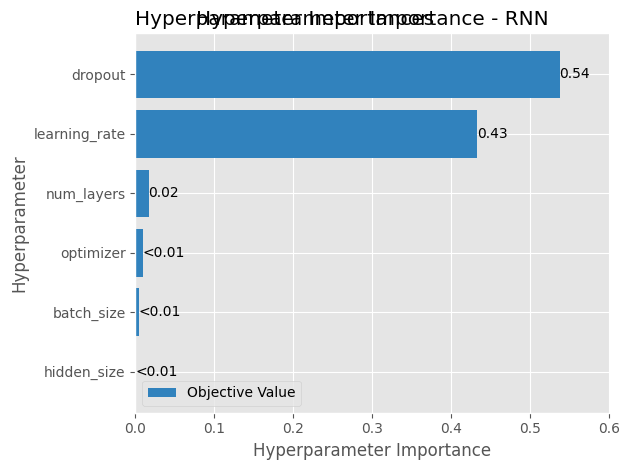

LSTM


/tmp/ipykernel_606/799184920.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(


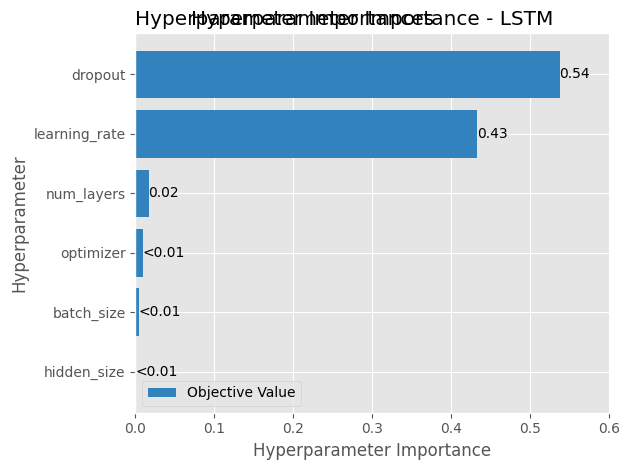

LSTM Attention


/tmp/ipykernel_606/799184920.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(


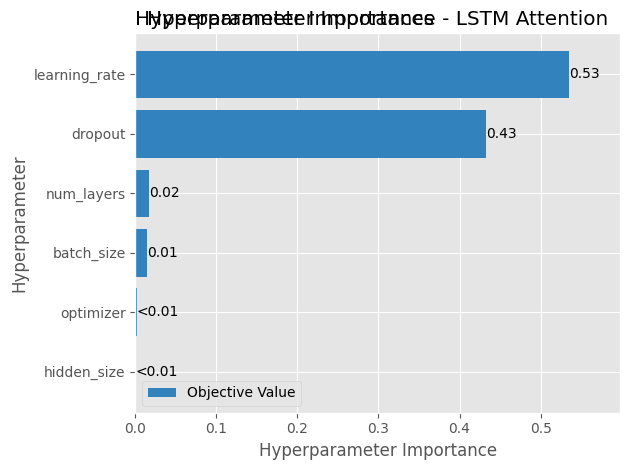

In [56]:
for model_name, study in studies.items():

    print(model_name)

    try:
        optuna.visualization.matplotlib.plot_param_importances(
            study
        )

        plt.title(f"Hyperparameter Importance - {model_name}")
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print("Importance plot unavailable:", e)

/tmp/ipykernel_606/2113779720.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(


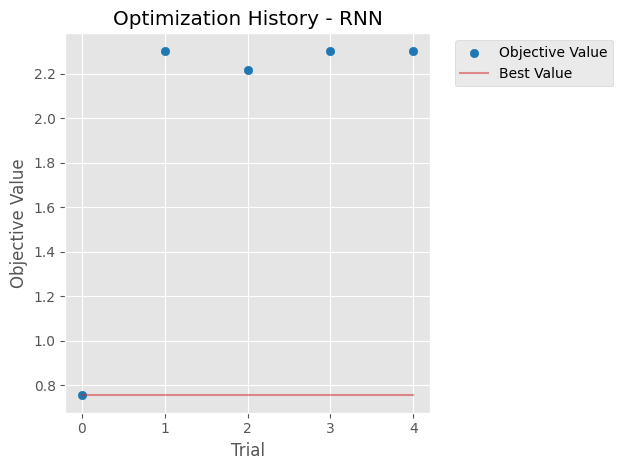

/tmp/ipykernel_606/2113779720.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(


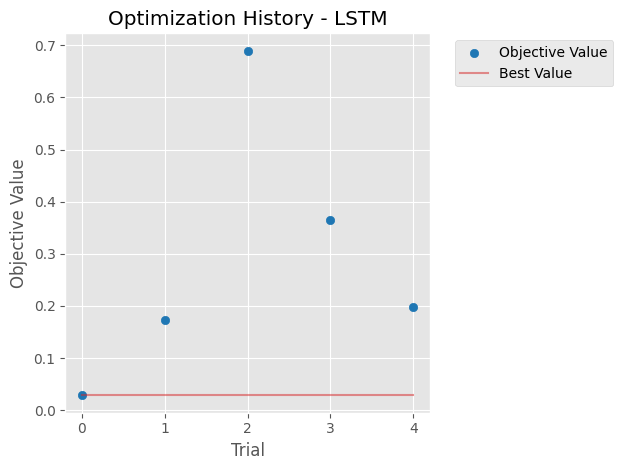

/tmp/ipykernel_606/2113779720.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(


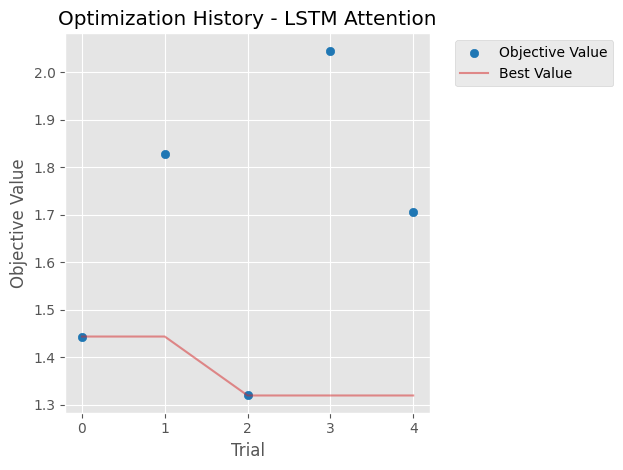

In [54]:
for model_name, study in studies.items():

    optuna.visualization.matplotlib.plot_optimization_history(
        study
    )

    plt.title(f"Optimization History - {model_name}")
    plt.tight_layout()
    plt.show()

- RNN : pada trial 1 menghasilkan validation loss paling kecil yaitu sekitar 0.7
- LSTM : pada trial 1 menghasilkan validation loss paling kecil yaitu sekitar 0.0
- LSTM Attention : pada trial 2 menghasilkan validation loss paling kecil yaitu sekitar 1.3

penyimpanan proses training

In [88]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import torch

SAVE_DIR = "/content/drive/MyDrive/Sequence_Copy_Experiment"

MODEL_DIR = os.path.join(SAVE_DIR, "saved_models")
PREDICTION_DIR = os.path.join(SAVE_DIR, "predictions")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PREDICTION_DIR, exist_ok=True)

print("Folder siap digunakan!")

Mounted at /content/drive
Folder siap digunakan!


##**Optimized Training**

In [89]:
trained_models = {
    scenario: {}
    for scenario in SCENARIOS
}

In [91]:
optimized_results = {}
optimized_models = {}
prediction_results = {}

for scenario in SCENARIOS:

    optimized_results[scenario] = {}
    optimized_models[scenario] = {}
    prediction_results[scenario] = {}

    for model_name, ModelClass in MODEL_CLASSES.items():

        print("\n" + "="*60)
        print(f"MODEL: {model_name} | SCENARIO: {scenario}")
        print("="*60)

        # Menggunakan best hyperparameters sebelumnya
        best_params = studies[model_name].best_params

        model = ModelClass(
            VOCAB_SIZE,
            best_params["hidden_size"],
            best_params["num_layers"],
            best_params["dropout"]
        ).to(device)

        dataset = DATASETS[scenario]

        # Final training
        trained_model, history, best_val_loss = train_model(
            model=model,
            train_inputs=dataset["train_inputs"],
            train_targets=dataset["train_targets"],
            val_inputs=dataset["val_inputs"],
            val_targets=dataset["val_targets"],
            learning_rate=best_params["learning_rate"],
            batch_size=best_params["batch_size"],
            optimizer_name=best_params["optimizer"],
            patience=EARLY_STOPPING_PATIENCE,
            max_epochs=NUM_EPOCHS
        )

        # Simpan history dan model
        optimized_results[scenario][model_name] = history
        optimized_models[scenario][model_name] = trained_model

        # Simpan model weights ke Google Drive
        model_filename = f"{scenario}_{model_name.replace(' ', '_')}.pth"

        torch.save(
            trained_model.state_dict(),
            os.path.join(MODEL_DIR, model_filename)
        )

        print("Best validation loss:", best_val_loss)
        print("Model weights berhasil disimpan!")


MODEL: RNN | SCENARIO: clean
Epoch 10/100 | Train Loss: 1.9606 | Val Loss: 1.9632 | Accuracy: 0.2458
Epoch 20/100 | Train Loss: 1.8286 | Val Loss: 1.8525 | Accuracy: 0.2750
Epoch 30/100 | Train Loss: 1.7669 | Val Loss: 1.7766 | Accuracy: 0.2915
Epoch 40/100 | Train Loss: 1.6423 | Val Loss: 1.6663 | Accuracy: 0.3238
Epoch 50/100 | Train Loss: 1.5357 | Val Loss: 1.5619 | Accuracy: 0.3506
Epoch 60/100 | Train Loss: 1.3755 | Val Loss: 1.4078 | Accuracy: 0.3961
Epoch 70/100 | Train Loss: 1.2246 | Val Loss: 1.2109 | Accuracy: 0.4702
Epoch 80/100 | Train Loss: 1.0965 | Val Loss: 1.1271 | Accuracy: 0.4955
Epoch 90/100 | Train Loss: 1.0181 | Val Loss: 1.0537 | Accuracy: 0.5230
Epoch 100/100 | Train Loss: 0.9454 | Val Loss: 1.0498 | Accuracy: 0.5208
Best validation loss: tensor(0.9841, device='cuda:0')
Model weights berhasil disimpan!

MODEL: LSTM | SCENARIO: clean
Epoch 10/100 | Train Loss: 1.0476 | Val Loss: 0.9857 | Accuracy: 0.5882
Epoch 20/100 | Train Loss: 0.5105 | Val Loss: 0.4776 | Accu

##**Evaluasi Model**

In [92]:
def show_sample_prediction(scenario, model_name, num_samples=5):

    dataset = DATASETS[scenario]

    inputs = dataset["test_inputs"][:num_samples].to(device)
    targets = dataset["test_targets"][:num_samples].to(device)

    model = optimized_models[scenario][model_name]
    model.eval()

    with torch.no_grad():
        outputs = model(inputs)

        predictions = outputs[:, -INPUT_LEN:, :].argmax(dim=-1)

    rows = []
    total_correct = 0
    total_numbers = 0

    for i in range(num_samples):

        sample = inputs[i].cpu().tolist()
        target = targets[i].cpu().tolist()
        predicted = predictions[i].cpu().tolist()

        correct_count = sum(
            t == p for t, p in zip(target, predicted)
        )

        accuracy = correct_count / len(target) * 100

        total_correct += correct_count
        total_numbers += len(target)

        rows.append({
            "Sample": i + 1,
            "Sample Data": sample,
            "Target": target,
            "Predicted": predicted,
            "Correct": f"{correct_count}/{len(target)}",
            "Accuracy (%)": round(accuracy, 2)
        })

    df = pd.DataFrame(rows)

    prediction_results[scenario][model_name] = df

    print(f"\nScenario: {scenario}")
    print(f"Model: {model_name}")

    display(df)

    overall_accuracy = total_correct / total_numbers * 100

    print(f"Total correct: {total_correct}/{total_numbers}")
    print(f"Overall Accuracy: {overall_accuracy:.2f}%")

    return df

In [93]:
for scenario in SCENARIOS:

    for model_name in MODEL_CLASSES.keys():

        show_sample_prediction(
            scenario=scenario,
            model_name=model_name,
            num_samples=5
        )


Scenario: clean
Model: RNN


,Sample,Sample Data,Target,Predicted,Correct,Accuracy (%)
0,1,"[2, 8, 7, 3, 1, 8, 3, 2, 8, 8, 10, 10, 10, 10,...","[2, 8, 7, 3, 1, 8, 3, 2, 8, 8]","[4, 2, 7, 4, 1, 3, 3, 2, 3, 2]",4/10,40.0
1,2,"[9, 8, 4, 1, 4, 1, 1, 9, 9, 2, 10, 10, 10, 10,...","[9, 8, 4, 1, 4, 1, 1, 9, 9, 2]","[9, 8, 4, 9, 4, 1, 1, 9, 7, 2]",8/10,80.0
2,3,"[3, 4, 3, 8, 0, 0, 7, 7, 5, 2, 10, 10, 10, 10,...","[3, 4, 3, 8, 0, 0, 7, 7, 5, 2]","[8, 3, 3, 3, 0, 0, 7, 7, 5, 4]",6/10,60.0
3,4,"[3, 2, 0, 8, 8, 4, 3, 9, 9, 7, 10, 10, 10, 10,...","[3, 2, 0, 8, 8, 4, 3, 9, 9, 7]","[4, 4, 1, 4, 3, 6, 2, 9, 1, 7]",2/10,20.0
4,5,"[5, 6, 8, 0, 1, 8, 7, 1, 1, 4, 10, 10, 10, 10,...","[5, 6, 8, 0, 1, 8, 7, 1, 1, 4]","[5, 2, 3, 0, 9, 3, 7, 1, 0, 2]",4/10,40.0


Total correct: 24/50
Overall Accuracy: 48.00%

Scenario: clean
Model: LSTM


,Sample,Sample Data,Target,Predicted,Correct,Accuracy (%)
0,1,"[2, 8, 7, 3, 1, 8, 3, 2, 8, 8, 10, 10, 10, 10,...","[2, 8, 7, 3, 1, 8, 3, 2, 8, 8]","[2, 8, 7, 3, 1, 8, 3, 2, 8, 8]",10/10,100.0
1,2,"[9, 8, 4, 1, 4, 1, 1, 9, 9, 2, 10, 10, 10, 10,...","[9, 8, 4, 1, 4, 1, 1, 9, 9, 2]","[9, 8, 4, 1, 4, 1, 1, 9, 9, 2]",10/10,100.0
2,3,"[3, 4, 3, 8, 0, 0, 7, 7, 5, 2, 10, 10, 10, 10,...","[3, 4, 3, 8, 0, 0, 7, 7, 5, 2]","[3, 4, 3, 8, 0, 0, 7, 7, 5, 2]",10/10,100.0
3,4,"[3, 2, 0, 8, 8, 4, 3, 9, 9, 7, 10, 10, 10, 10,...","[3, 2, 0, 8, 8, 4, 3, 9, 9, 7]","[3, 2, 0, 8, 8, 4, 3, 9, 9, 7]",10/10,100.0
4,5,"[5, 6, 8, 0, 1, 8, 7, 1, 1, 4, 10, 10, 10, 10,...","[5, 6, 8, 0, 1, 8, 7, 1, 1, 4]","[5, 6, 8, 0, 1, 8, 7, 1, 1, 4]",10/10,100.0


Total correct: 50/50
Overall Accuracy: 100.00%

Scenario: clean
Model: LSTM Attention


,Sample,Sample Data,Target,Predicted,Correct,Accuracy (%)
0,1,"[2, 8, 7, 3, 1, 8, 3, 2, 8, 8, 10, 10, 10, 10,...","[2, 8, 7, 3, 1, 8, 3, 2, 8, 8]","[2, 8, 8, 3, 3, 1, 2, 2, 8, 8]",6/10,60.0
1,2,"[9, 8, 4, 1, 4, 1, 1, 9, 9, 2, 10, 10, 10, 10,...","[9, 8, 4, 1, 4, 1, 1, 9, 9, 2]","[9, 8, 4, 4, 1, 1, 1, 9, 9, 9]",7/10,70.0
2,3,"[3, 4, 3, 8, 0, 0, 7, 7, 5, 2, 10, 10, 10, 10,...","[3, 4, 3, 8, 0, 0, 7, 7, 5, 2]","[3, 3, 3, 8, 0, 0, 7, 7, 5, 5]",8/10,80.0
3,4,"[3, 2, 0, 8, 8, 4, 3, 9, 9, 7, 10, 10, 10, 10,...","[3, 2, 0, 8, 8, 4, 3, 9, 9, 7]","[3, 2, 8, 8, 8, 3, 4, 9, 9, 9]",6/10,60.0
4,5,"[5, 6, 8, 0, 1, 8, 7, 1, 1, 4, 10, 10, 10, 10,...","[5, 6, 8, 0, 1, 8, 7, 1, 1, 4]","[5, 6, 8, 1, 1, 8, 1, 1, 4, 4]",7/10,70.0


... (9 outputs left out)

,Sample,Sample Data,Target,Predicted,Correct,Accuracy (%)
0,1,"[1, 1, 9, 8, 3, 1, 0, 0, 5, 0, 6, 4, 10, 1, 5,...","[1, 1, 9, 8, 3, 1, 0, 0, 5, 0]","[1, 1, 9, 8, 3, 1, 0, 0, 5, 0]",10/10,100.0
1,2,"[6, 0, 1, 0, 1, 0, 6, 0, 5, 9, 2, 1, 1, 4, 10,...","[6, 0, 1, 0, 1, 0, 6, 0, 5, 9]","[6, 0, 1, 1, 1, 0, 6, 0, 5, 9]",9/10,90.0
2,3,"[3, 4, 1, 2, 4, 1, 5, 0, 3, 5, 10, 3, 10, 0, 8...","[3, 4, 1, 2, 4, 1, 5, 0, 3, 5]","[3, 4, 1, 2, 4, 1, 5, 0, 3, 5]",10/10,100.0
3,4,"[2, 0, 9, 8, 8, 1, 2, 2, 0, 3, 5, 3, 1, 10, 8,...","[2, 0, 9, 8, 8, 1, 2, 2, 0, 3]","[2, 0, 9, 8, 8, 1, 2, 2, 0, 3]",10/10,100.0
4,5,"[6, 7, 1, 6, 4, 3, 5, 8, 1, 3, 3, 1, 10, 5, 10...","[6, 7, 1, 6, 4, 3, 5, 8, 1, 3]","[6, 7, 1, 6, 4, 3, 5, 8, 1, 3]",10/10,100.0


Total correct: 49/50
Overall Accuracy: 98.00%

Scenario: noise_random
Model: LSTM Attention


,Sample,Sample Data,Target,Predicted,Correct,Accuracy (%)
0,1,"[1, 1, 9, 8, 3, 1, 0, 0, 5, 0, 6, 4, 10, 1, 5,...","[1, 1, 9, 8, 3, 1, 0, 0, 5, 0]","[7, 7, 7, 8, 3, 1, 0, 0, 7, 7]",5/10,50.0
1,2,"[6, 0, 1, 0, 1, 0, 6, 0, 5, 9, 2, 1, 1, 4, 10,...","[6, 0, 1, 0, 1, 0, 6, 0, 5, 9]","[7, 7, 7, 7, 7, 7, 6, 0, 0, 7]",2/10,20.0
2,3,"[3, 4, 1, 2, 4, 1, 5, 0, 3, 5, 10, 3, 10, 0, 8...","[3, 4, 1, 2, 4, 1, 5, 0, 3, 5]","[4, 4, 4, 4, 1, 1, 1, 0, 7, 7]",3/10,30.0
3,4,"[2, 0, 9, 8, 8, 1, 2, 2, 0, 3, 5, 3, 1, 10, 8,...","[2, 0, 9, 8, 8, 1, 2, 2, 0, 3]","[7, 7, 7, 8, 8, 2, 2, 2, 0, 7]",5/10,50.0
4,5,"[6, 7, 1, 6, 4, 3, 5, 8, 1, 3, 3, 1, 10, 5, 10...","[6, 7, 1, 6, 4, 3, 5, 8, 1, 3]","[7, 7, 1, 1, 1, 5, 5, 8, 3, 3]",5/10,50.0


Total correct: 20/50
Overall Accuracy: 40.00%


- Clean
1. RNN : Memiliki overal akurasi 48%
2. LSTM : Memiliki overal akurasi 100%
3. LSTM Attention : Memiliki overal akurasi 68%
- Noise End
1. RNN : Memiliki overal akurasi 100%
2. LSTM : Memiliki overal akurasi 100%
3. LSTM Attention : Memiliki overal akurasi 44%
- Noise Random
1. RNN : Memiliki overal akurasi 46%
2. LSTM : Memiliki overal akurasi 98%
3. LSTM Attention : Memiliki overal akurasi 40%

In [94]:
test_results = []

for scenario in SCENARIOS:

    dataset = DATASETS[scenario]

    for model_name in MODEL_CLASSES:

        model = optimized_models[scenario][model_name]

        metrics = evaluate_model(
            model,
            dataset["test_inputs"],
            dataset["test_targets"]
        )

        test_results.append({
            "Scenario": scenario,
            "Model": model_name,
            "Test Loss": metrics["loss"],
            "Test Accuracy": metrics["accuracy"],
            "Test MAE": metrics["mae"],
            "Test RMSE": metrics["rmse"]
        })

df_test = pd.DataFrame(test_results)

df_test

,Scenario,Model,Test Loss,Test Accuracy,Test MAE,Test RMSE
0,clean,RNN,"tensor(0.9944, device='cuda:0')",0.5554,1.6025,2.871184
1,clean,LSTM,"tensor(0.0093, device='cuda:0')",0.9973,0.0109,0.242693
2,clean,LSTM Attention,"tensor(0.7216, device='cuda:0')",0.7327,0.9901,2.231972
3,noise_end,RNN,"tensor(0.0392, device='cuda:0')",0.9939,0.0266,0.376298
4,noise_end,LSTM,"tensor(0.0100, device='cuda:0')",0.9964,0.0126,0.243310
5,noise_end,LSTM Attention,"tensor(1.5841, device='cuda:0')",0.3902,1.8052,2.676789
6,noise_random,RNN,"tensor(1.4534, device='cuda:0')",0.4343,1.9243,2.968754
7,noise_random,LSTM,"tensor(0.0093, device='cuda:0')",0.9971,0.0092,0.205913
8,noise_random,LSTM Attention,"tensor(1.6304, device='cuda:0')",0.3795,2.1694,3.230665


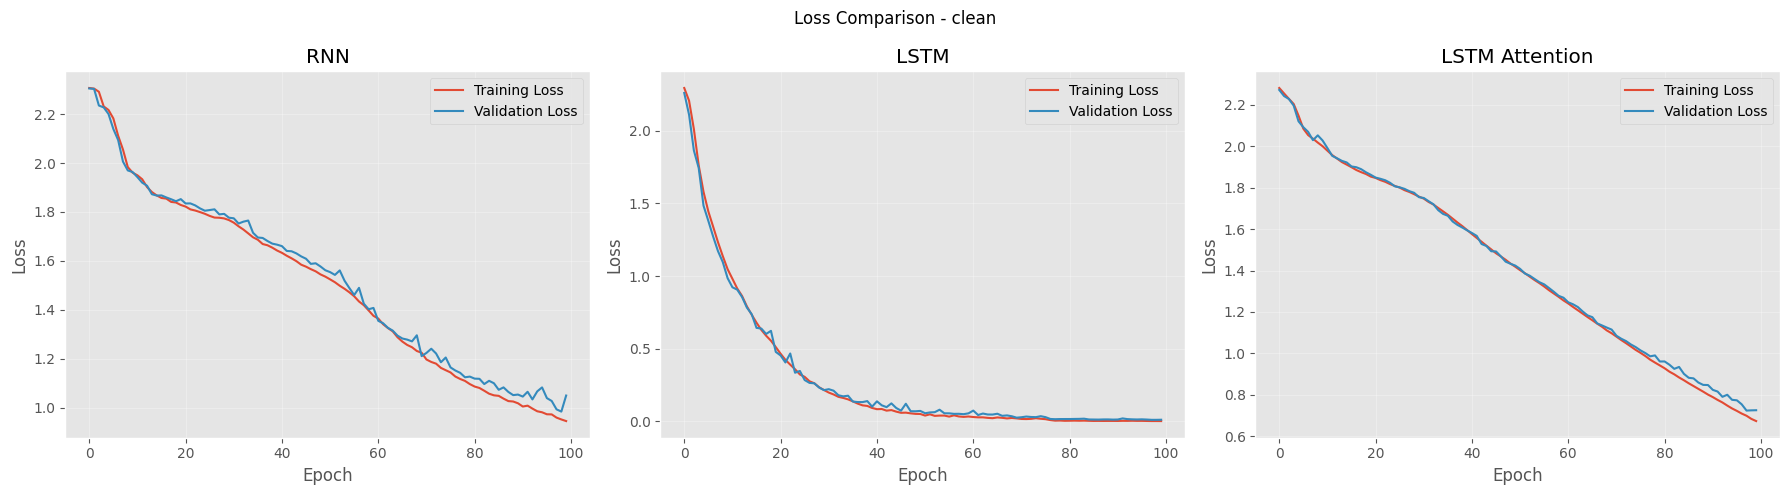

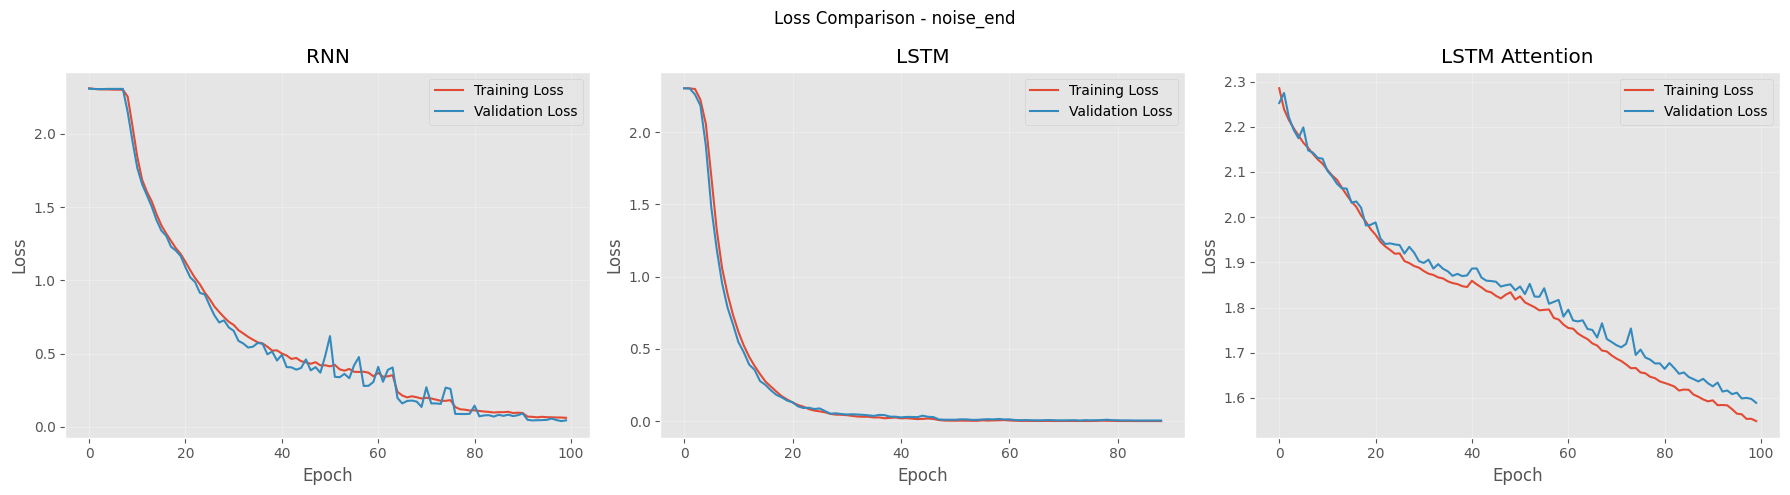

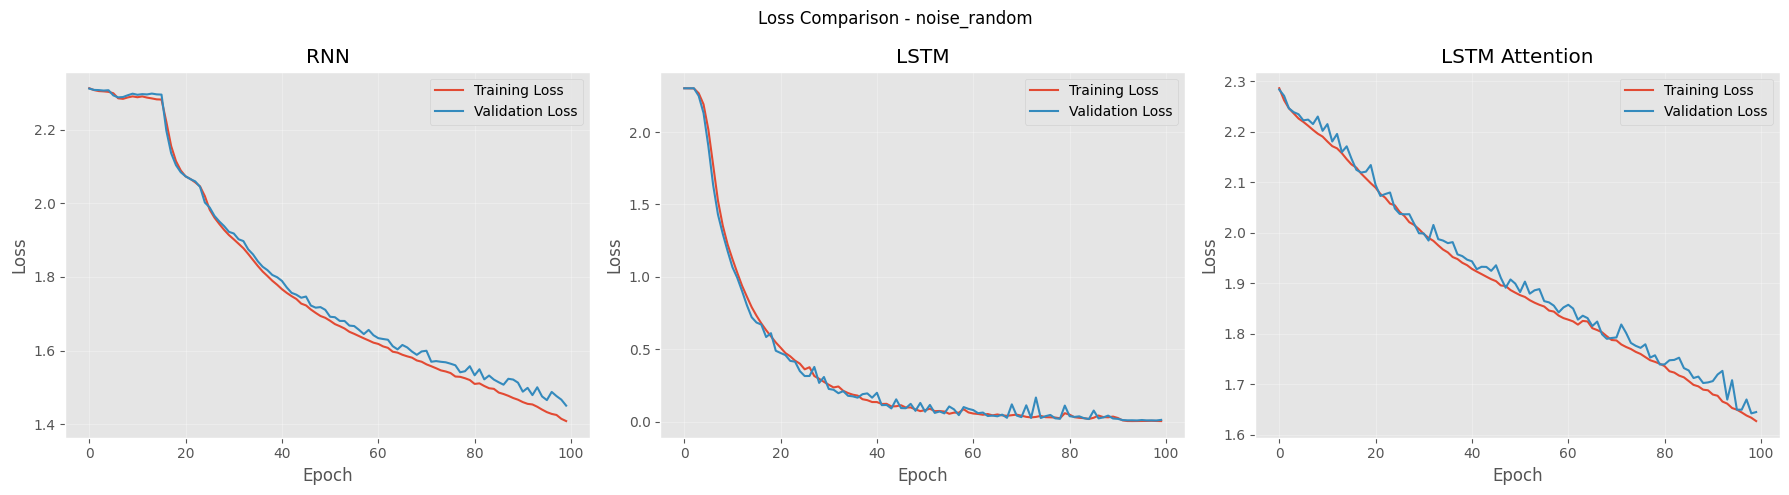

In [95]:

for scenario in SCENARIOS:

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, model_name in zip(axes, MODEL_CLASSES):

        history = optimized_results[scenario][model_name]

        # Convert GPU tensors to CPU NumPy arrays
        train_loss = [
            x.detach().cpu().item() if torch.is_tensor(x) else x
            for x in history["train_loss"]
        ]

        val_loss = [
            x.detach().cpu().item() if torch.is_tensor(x) else x
            for x in history["val_loss"]
        ]

        ax.plot(
            train_loss,
            label="Training Loss"
        )

        ax.plot(
            val_loss,
            label="Validation Loss"
        )

        ax.set_title(model_name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.suptitle(f"Loss Comparison - {scenario}")
    plt.tight_layout()
    plt.show()


- **Clean**
1. RNN : Training loss dan validation loss mengalami penurunan hingga 1.0. Validation loss mengalami fluktuasi pada epoch 60-80. Proses konvergensinya relatif lambat dan masih terdapat fluktuasi pada performa validasi.
2. LSTM : Training loss dan validation loss mengalami penurunan drastis di epoch 20, dan di akhir berhasil mendapatkan training loss dan validation loss hingga 0.0. Proses konvergensinya sangat cepat.
3. LSTM Attention : Training loss dan validation loss mengalami penurunan hingga 0.6. Proses konvergensinya sangat stabil.


- **Noise End**
1. RNN : Training loss dan validation loss mengalami penurunan hingga 0.0. Validation loss mengalami fluktuasi pada epoch 40-80. Proses konvergensinya sangat cepat di epoch awal, tetapi agak stabil dipertengahan hingga akhir.
2. LSTM : Training loss dan validation loss mengalami penurunan drastis di epoch 20, dan di akhir berhasil mendapatkan training loss dan validation loss hingga 0.0. Proses konvergensinya sangat cepat.
3. LSTM Attention : Training loss dan validation loss mengalami penurunan hingga 1.6. Validation loss banyak mengalami fluktuasi dari epoch 20-100. Proses konvergensinya agak stabil.


- **Noise Random**
1. RNN : Training loss dan validation loss mengalami penurunan hingga 1.4. Validation loss mengalami fluktuasi pada epoch 40-80. Proses konvergensinya sangat cepat di epoch awal, tetapi agak stabil dipertengahan hingga akhir.
2. LSTM : Training loss dan validation loss mengalami penurunan drastis di epoch 20, dan di akhir berhasil mendapatkan training loss dan validation loss hingga 0.0. Validation loss mengalami fluktuasi di epoch 20--80. Proses konvergensinya sangat cepat.
3. LSTM Attention : Training loss dan validation loss mengalami penurunan hingga 1.6. Validation loss banyak mengalami fluktuasi. Proses konvergensinya  stabil.

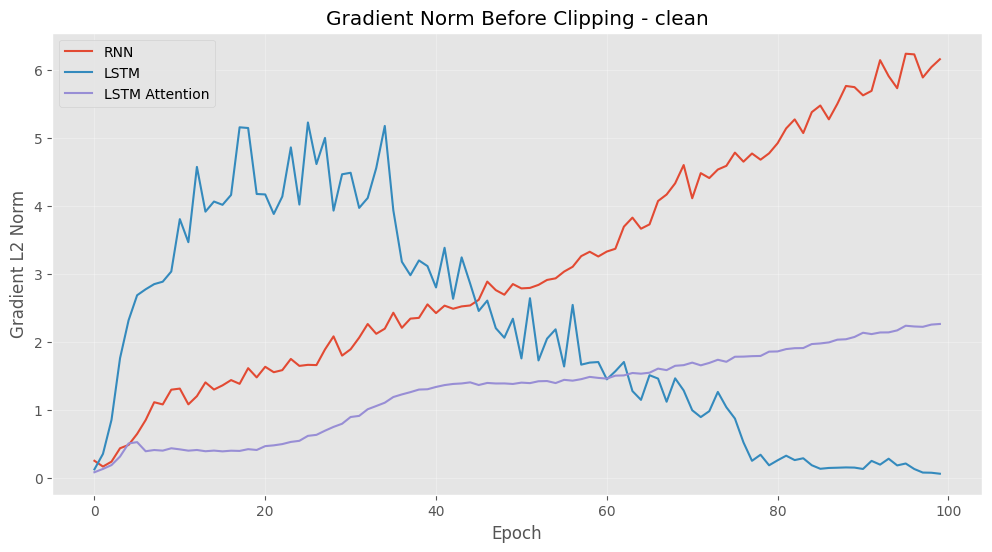

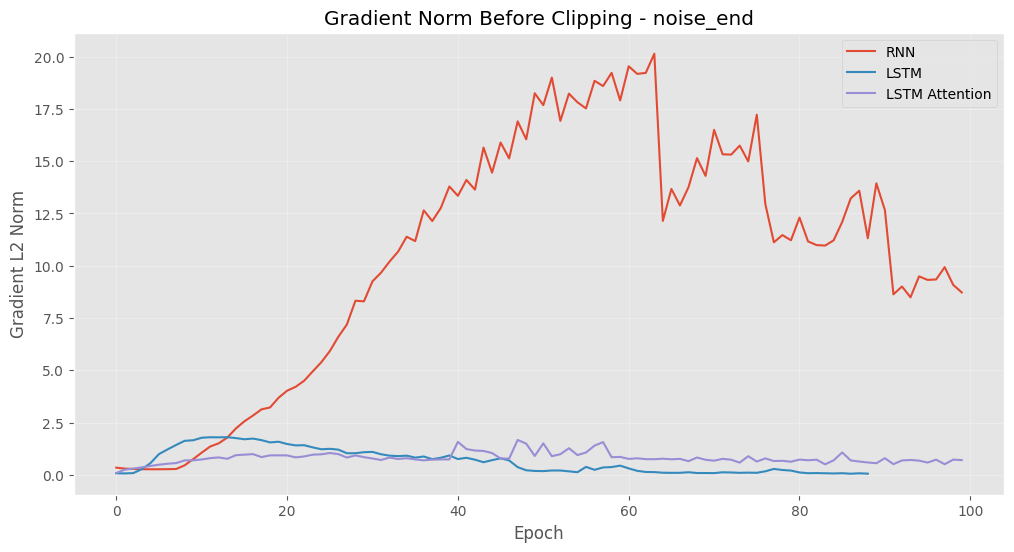

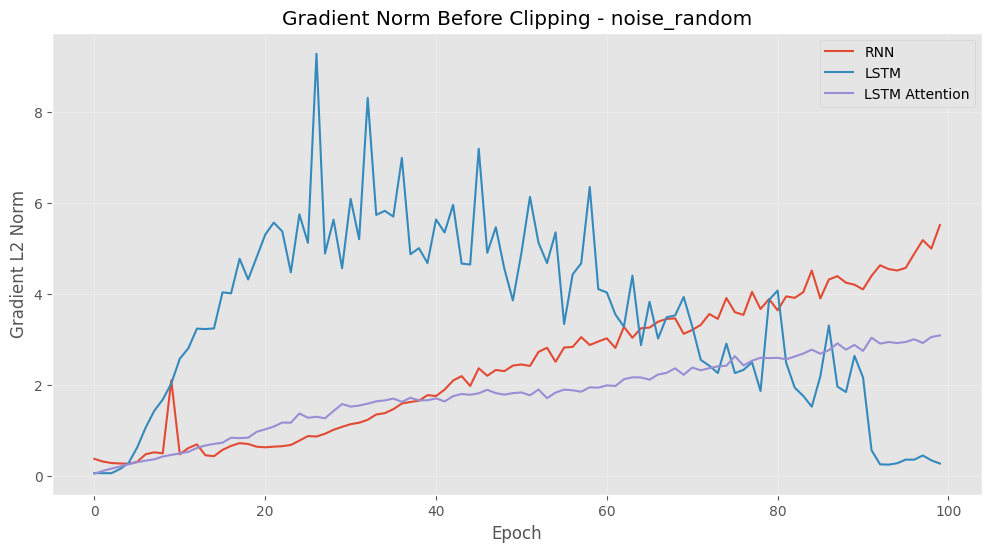

In [96]:
for scenario in SCENARIOS:

    plt.figure(figsize=(12, 6))

    for model_name in MODEL_CLASSES:

        history = optimized_results[scenario][model_name]

        plt.plot(
            history["gradient_norm"],
            label=model_name
        )

    plt.title(f"Gradient Norm Before Clipping - {scenario}")
    plt.xlabel("Epoch")
    plt.ylabel("Gradient L2 Norm")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

gradient norm setelah diclipping

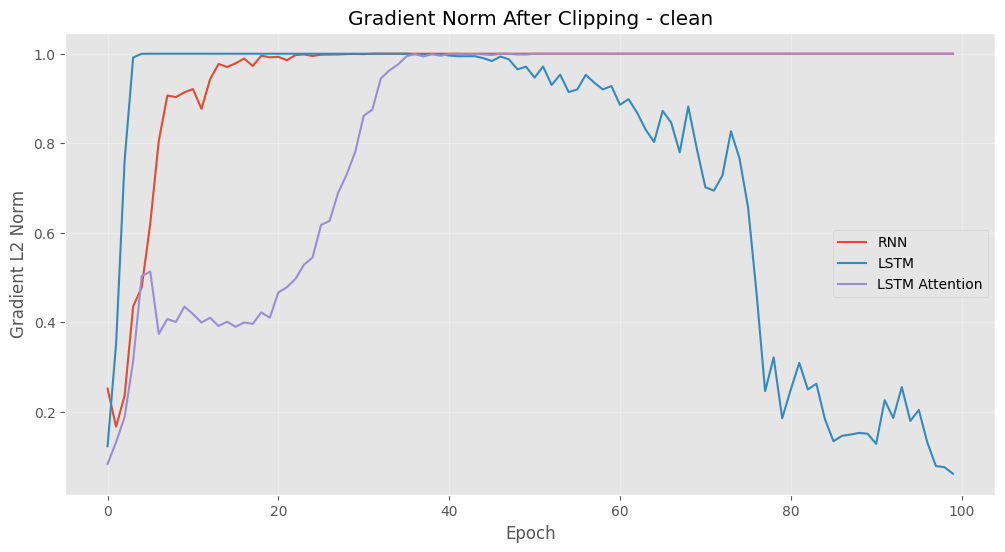

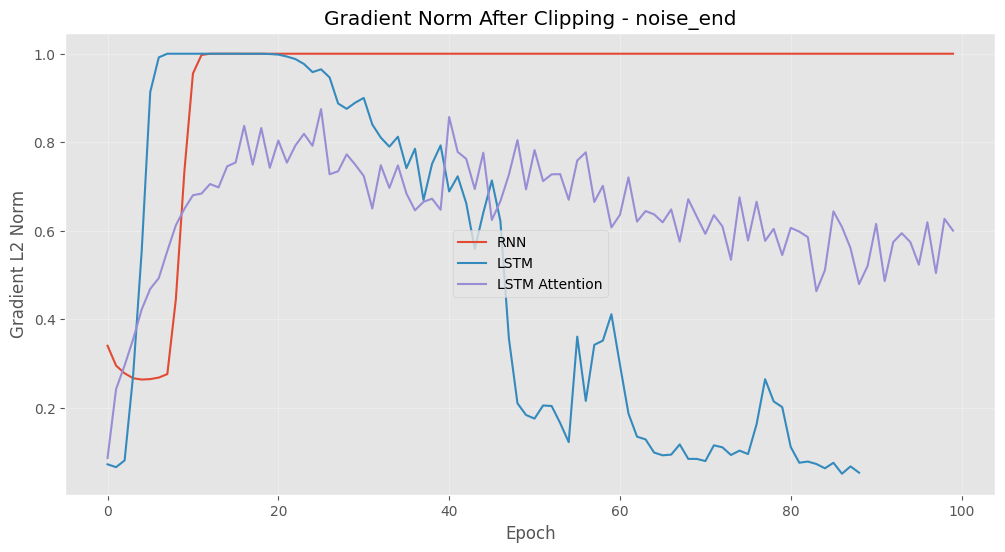

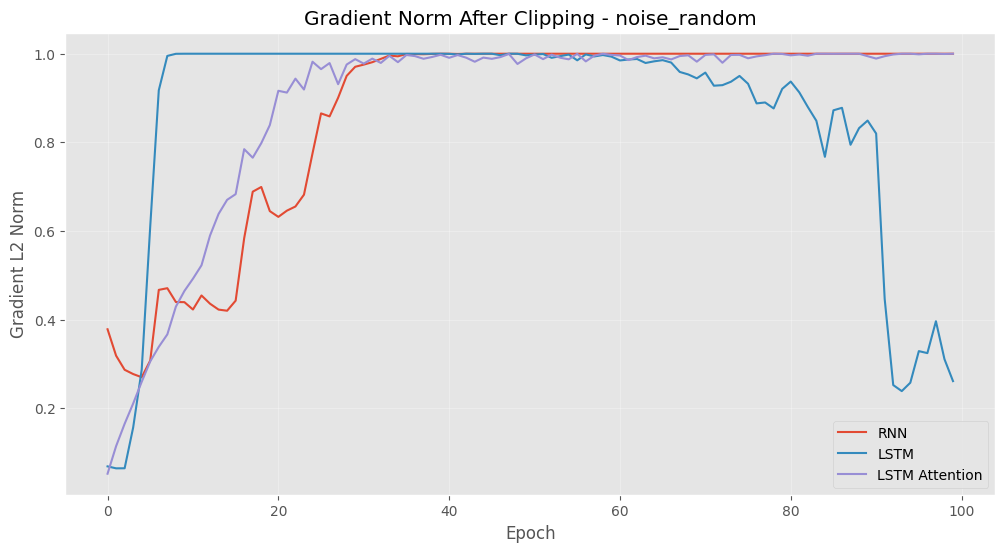

In [97]:
for scenario in SCENARIOS:

    plt.figure(figsize=(12, 6))

    for model_name in MODEL_CLASSES:

        history = optimized_results[scenario][model_name]

        plt.plot(
            history["gradient_after_clip"],
            label=model_name
        )

    plt.title(f"Gradient Norm After Clipping - {scenario}")
    plt.xlabel("Epoch")
    plt.ylabel("Gradient L2 Norm")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

- **RNN** : Terdapat sensitivitas pada perubahan pola noise. Gradient clipping membantu mengendalikan gradien yang besar, tapi tidak dapat sepenuhnya mengatasi learning di random noise.
- **LSTM** : Melakukan generalisasi yang sangat baik pada clean, noise end, dan noise random. Gradien norm mengalami fluktuasi, tapi menghasilkan akurasi yang tinggi.
- **LSTM Attention**: Perubahan gradien yang bertahap. Memiliki akurasi yang lebih kurang daripada LSTM.

akurasi

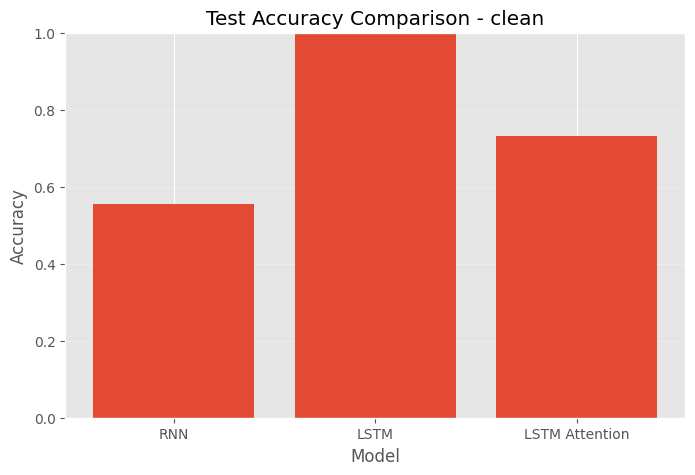

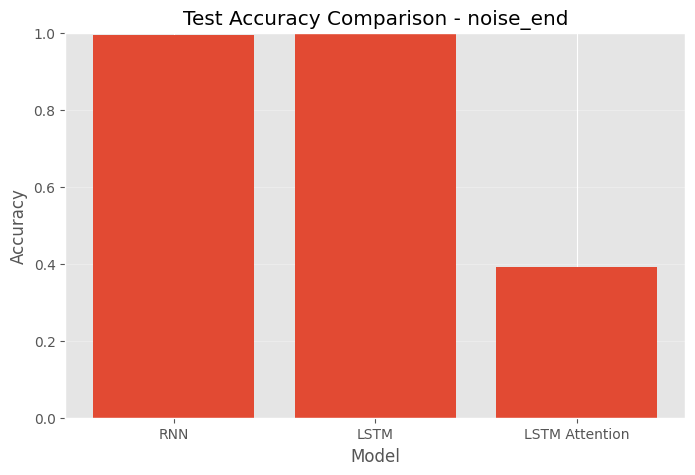

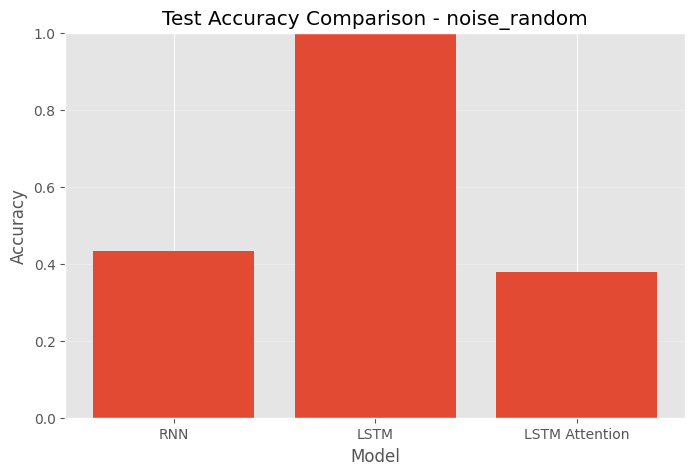

In [98]:
for scenario in SCENARIOS:

    data = df_test[
        df_test["Scenario"] == scenario
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        data["Model"],
        data["Test Accuracy"]
    )

    plt.title(f"Test Accuracy Comparison - {scenario}")
    plt.xlabel("Model")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)

    plt.show()

MAE dan RSME

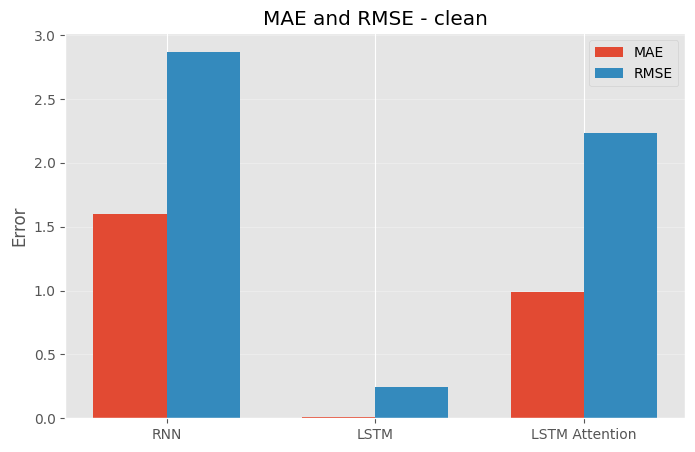

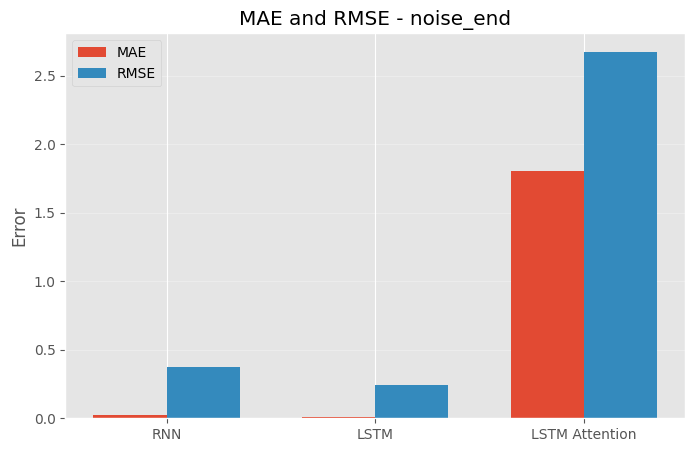

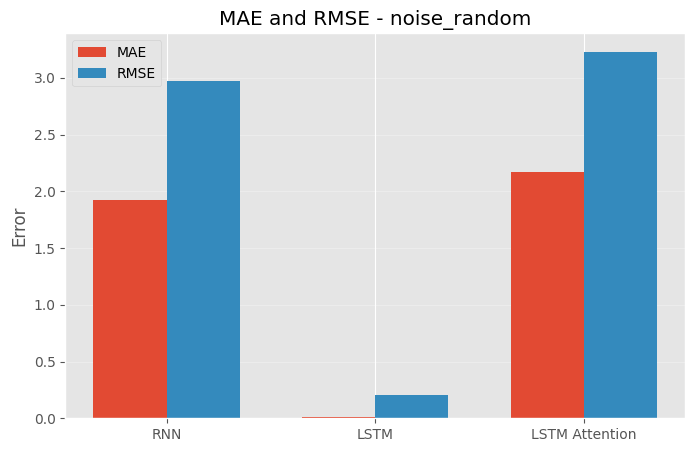

In [99]:
for scenario in SCENARIOS:

    data = df_test[
        df_test["Scenario"] == scenario
    ]

    x = np.arange(len(data))
    width = 0.35

    plt.figure(figsize=(8, 5))

    plt.bar(
        x - width/2,
        data["Test MAE"],
        width,
        label="MAE"
    )

    plt.bar(
        x + width/2,
        data["Test RMSE"],
        width,
        label="RMSE"
    )

    plt.xticks(x, data["Model"])
    plt.title(f"MAE and RMSE - {scenario}")
    plt.ylabel("Error")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)

    plt.show()

Analisis Robusness terhadap Noise

In [100]:
accuracy_pivot = df_test.pivot(
    index="Model",
    columns="Scenario",
    values="Test Accuracy"
)

accuracy_pivot

Scenario,clean,noise_end,noise_random
Model,,,
LSTM,0.9973,0.9964,0.9971
LSTM Attention,0.7327,0.3902,0.3795
RNN,0.5554,0.9939,0.4343


In [101]:
accuracy_pivot["Noise End Degradation"] = (
    accuracy_pivot["clean"] -
    accuracy_pivot["noise_end"]
)

accuracy_pivot["Noise Random Degradation"] = (
    accuracy_pivot["clean"] -
    accuracy_pivot["noise_random"]
)

accuracy_pivot

Scenario,clean,noise_end,noise_random,Noise End Degradation,Noise Random Degradation
Model,,,,,
LSTM,0.9973,0.9964,0.9971,0.0009,0.0002
LSTM Attention,0.7327,0.3902,0.3795,0.3425,0.3532
RNN,0.5554,0.9939,0.4343,-0.4385,0.1211


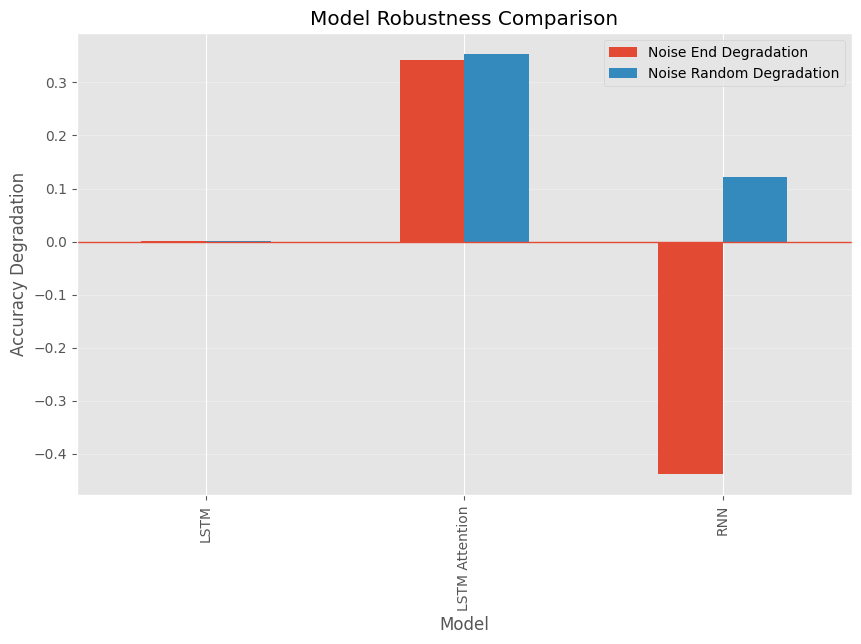

In [102]:
degradation = accuracy_pivot[
    ["Noise End Degradation", "Noise Random Degradation"]
]

degradation.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Robustness Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy Degradation")
plt.axhline(0, linewidth=1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [103]:
import pandas as pd
import numpy as np

rows = []

for scenario in SCENARIOS:

    for model_name in MODEL_CLASSES.keys():

        history = optimized_results[scenario][model_name]

        rows.append({
            "Scenario": scenario,
            "Model": model_name,
            "Train Loss": history["train_loss"][-1],
            "Validation Loss": history["val_loss"][-1],
            "Accuracy": history["accuracy"][-1],
            "MAE": history["mae"][-1],
            "RMSE": history["rmse"][-1]
        })

results_df = pd.DataFrame(rows)

display(
    results_df.round(4).style
    .format({
        "Train Loss": "{:.4f}",
        "Validation Loss": "{:.4f}",
        "Accuracy": "{:.4f}",
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}"
    })
    .background_gradient(subset=["Accuracy"], cmap="Greens")
    .background_gradient(
        subset=["Validation Loss", "MAE", "RMSE"],
        cmap="Reds"
    )
)

,Scenario,Model,Train Loss,Validation Loss,Accuracy,MAE,RMSE
0,clean,RNN,0.9454,1.0498,0.5208,1.8228,3.1162
1,clean,LSTM,0.0010,0.0102,0.9966,0.0145,0.2948
2,clean,LSTM Attention,0.6739,0.7262,0.7247,0.9846,2.1935
3,noise_end,RNN,0.0610,0.0435,0.9921,0.0335,0.4295
4,noise_end,LSTM,0.0009,0.0047,0.9984,0.0065,0.1868
5,noise_end,LSTM Attention,1.5487,1.5891,0.3952,1.7730,2.6309
6,noise_random,RNN,1.4082,1.4502,0.4356,1.9539,3.0080
7,noise_random,LSTM,0.0031,0.0112,0.9962,0.0132,0.2433
8,noise_random,LSTM Attention,1.6274,1.6453,0.3641,2.1613,3.1871


#**Kesimpulan**


Berdasarkan hasil pengujian pada ketiga skenario, LSTM memperoleh hasil yang paling baik dibandingkan RNN dan LSTM Attention.

1. Clean: LSTM memperoleh akurasi sebesar 99,66%, lebih tinggi dibandingkan RNN (52,08%) dan LSTM Attention (72,47%). LSTM juga memiliki nilai loss paling rendah dan proses training yang lebih cepat mencapai konvergensi.

2. Noise End: RNN dan LSTM sama-sama memperoleh akurasi yang tinggi, yaitu 99,21% dan 99,84%. Sementara itu, LSTM Attention hanya memperoleh akurasi 39,52%. Hal ini menunjukkan bahwa noise yang ditempatkan di bagian akhir tidak terlalu memengaruhi performa RNN dan LSTM.

3. Noise Random: Terlihat perbedaan yang cukup besar antara ketiga model. LSTM tetap memperoleh akurasi 99,62%, sedangkan RNN dan LSTM Attention hanya memperoleh 43,56% dan 36,41%. Artinya, LSTM masih mampu memprediksi sequence dengan baik meskipun noise ditempatkan secara acak.

#**Insight**

LSTM Attention: Memiliki perubahan gradien yang relatif bertahap, tetapi hasil prediksinya masih belum sebaik LSTM. Penambahan attention pada model ini belum memberikan hasil yang lebih baik dalam eksperimen yang dilakukan.
- RNN:  Performa RNN cukup baik pada skenario clean dan noise_end, tetapi mengalami penurunan yang cukup besar pada noise_random. Gradient clipping membantu mengendalikan gradien, tetapi RNN masih kesulitan ketika noise ditempatkan secara acak.

- LSTM: Menjadi model dengan hasil terbaik pada ketiga skenario. Meskipun terdapat perubahan pola gradien selama training, LSTM memiliki akurasi di atas 99%.

- LSTM Attention: Memiliki perubahan gradien yang relatif bertahap, tapi performa prediksinya masih rendah. Penambahan model ini belum memberikan hasil yang lebih baik dalam eksperimen yang dilakukan.